# Telco Customer Churn — Model Evaluation
### CRISP-DM: Modeling + Evaluation Phase
This notebook implements the **Modeling** and **Evaluation** phases of the CRISP-DM process for the Telco Customer Churn dataset. It assumes Business Understanding and Data Understanding/Preparation (EDA, cleaning) were done in an earlier notebook.

**Pipeline:** load cleaned data → encode → split → scale → SMOTE (train only) → train 5 baseline models → evaluate with multiple metrics → tune the Random Forest → compare ensembles → pick a deployment threshold → save the final model.

> **Note on results in this notebook:** outputs shown are from one run with `random_state=42`. Exact numbers will shift slightly with different data versions or library versions, but the *relative ranking* of models and the overall conclusions should hold.


## Step 1 — Imports

In [34]:
# This cell only matters if you're running on Google Colab and your CSV lives on Drive.
# If you're running locally / on Kaggle / elsewhere, skip this cell.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    ON_COLAB = True
except ImportError:
    ON_COLAB = False
    print('Not running on Colab — skipping Drive mount.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42  # single source of truth for reproducibility, used everywhere below

# Preprocessing
from sklearn.model_selection import train_test_split, RandomizedSearchCV, learning_curve, StratifiedKFold
from sklearn.preprocessing import StandardScaler

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# Imbalance handling
from imblearn.over_sampling import SMOTE

# Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, classification_report,
    confusion_matrix, roc_auc_score, average_precision_score,
    RocCurveDisplay, PrecisionRecallDisplay
)

import joblib

print('All imports OK!')


All imports OK!


## Step 2 — Load & Prepare Data

In [36]:
# ----- CHANGE THIS PATH if needed -----
DATA_PATH = '/content/drive/MyDrive/Colab Notebooks/churn app/WA_Fn-UseC_-Telco-Customer-Churn.csv' if ON_COLAB \
    else 'WA_Fn-UseC_-Telco-Customer-Churn.csv'

df = pd.read_csv(DATA_PATH)

# --- Fix TotalCharges: it's read as text because 11 rows are blank strings (new customers, tenure=0) ---
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
n_missing = df['TotalCharges'].isna().sum()
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())
print(f'TotalCharges: {n_missing} missing values imputed with the median.')

# --- Encode binary Yes/No columns ---
binary_cols = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']
for col in binary_cols:
    df[col] = df[col].map({'Yes': 1, 'No': 0})

# --- One-hot encode multi-category columns ---
df = pd.get_dummies(df, columns=[
    'gender', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaymentMethod'
], drop_first=True)

# --- Drop the ID column (not predictive, just a row identifier) ---
df.drop('customerID', axis=1, inplace=True)

print('Shape:', df.shape)
print('Churn distribution (%):')
print(df['Churn'].value_counts(normalize=True).mul(100).round(1))


TotalCharges: 11 missing values imputed with the median.
Shape: (7043, 31)
Churn distribution (%):
Churn
0    73.5
1    26.5
Name: proportion, dtype: float64


## Step 3 — Train/Test Split + Scaling + SMOTE

In [37]:
X = df.drop('Churn', axis=1)
y = df['Churn']

# Split BEFORE any scaling/resampling, so the test set stays a clean, untouched holdout
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f'Train churn rate: {y_train.mean():.3f}  |  Test churn rate: {y_test.mean():.3f}')

# Scale: fit ONLY on training data, then apply the same transform to test data
# (fitting on test data would leak test-set statistics into training -> optimistic bias)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# SMOTE on the TRAINING set only — never resample the test set.
# The test set must keep the real-world 73.5/26.5 imbalance, or every metric
# computed on it (precision, recall, ROC-AUC...) would be measuring performance
# on a distribution that doesn't exist in production.
smote = SMOTE(random_state=RANDOM_STATE)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

print('Training set after SMOTE:', X_train_res.shape)
print('Class balance after SMOTE:')
print(pd.Series(y_train_res).value_counts())


Train churn rate: 0.265  |  Test churn rate: 0.265
Training set after SMOTE: (8278, 30)
Class balance after SMOTE:
Churn
0    4139
1    4139
Name: count, dtype: int64


## Step 4 — Train All Models (Default Parameters)

In [38]:
# Note: Logistic Regression, SVM, and KNN are distance/gradient-based and need
# scaled features (X_train_res is already scaled). Decision Tree and Random Forest
# don't strictly need scaling, but training them on the same scaled+SMOTE'd data
# keeps the comparison fair and the code simple.
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Decision Tree':       DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest':       RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
    'SVM':                 SVC(probability=True, random_state=RANDOM_STATE),
    'KNN':                 KNeighborsClassifier(n_neighbors=5)
}

for name, model in models.items():
    model.fit(X_train_res, y_train_res)
    print(f'{name} — trained ✓')


Logistic Regression — trained ✓
Decision Tree — trained ✓
Random Forest — trained ✓
SVM — trained ✓
KNN — trained ✓


## Step 5 — Evaluation 1: Full Metrics Table (Accuracy, Precision, Recall, F1, MCC)

In [39]:
results = []

for name, model in models.items():
    y_pred  = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    results.append({
        'Model':     name,
        'Accuracy':  round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall':    round(recall_score(y_test, y_pred), 4),
        'F1-Score':  round(f1_score(y_test, y_pred), 4),
        'MCC':       round(matthews_corrcoef(y_test, y_pred), 4),
        'ROC-AUC':   round(roc_auc_score(y_test, y_proba), 4),
        'PR-AUC':    round(average_precision_score(y_test, y_proba), 4)
    })

results_df = pd.DataFrame(results).set_index('Model')

# BUG FIX: the original notebook built this table but never printed/displayed it,
# so the single most important comparison table in the whole notebook never showed up.
# Sorting by MCC (not Accuracy) because Accuracy is misleading on a 73.5/26.5 imbalanced
# problem -- a model that always predicts "No Churn" would still score ~73.5% accuracy.
display(results_df.sort_values('MCC', ascending=False)
        .style.background_gradient(subset=['MCC', 'F1-Score', 'ROC-AUC'], cmap='Greens')
        .format('{:.4f}'))


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC,PR-AUC
Model,,,,,,,
Logistic Regression,0.7381,0.5042,0.7968,0.6176,0.4597,0.8403,0.6271
SVM,0.7573,0.5316,0.7193,0.6114,0.4513,0.8164,0.5832
Random Forest,0.7736,0.5711,0.5909,0.5808,0.4259,0.8241,0.5983
KNN,0.6891,0.4446,0.6872,0.5399,0.3385,0.7502,0.4586
Decision Tree,0.7289,0.4904,0.5481,0.5177,0.3309,0.6709,0.3888


## Step 6 — Evaluation 2: Confusion Matrices (All Models Side by Side)

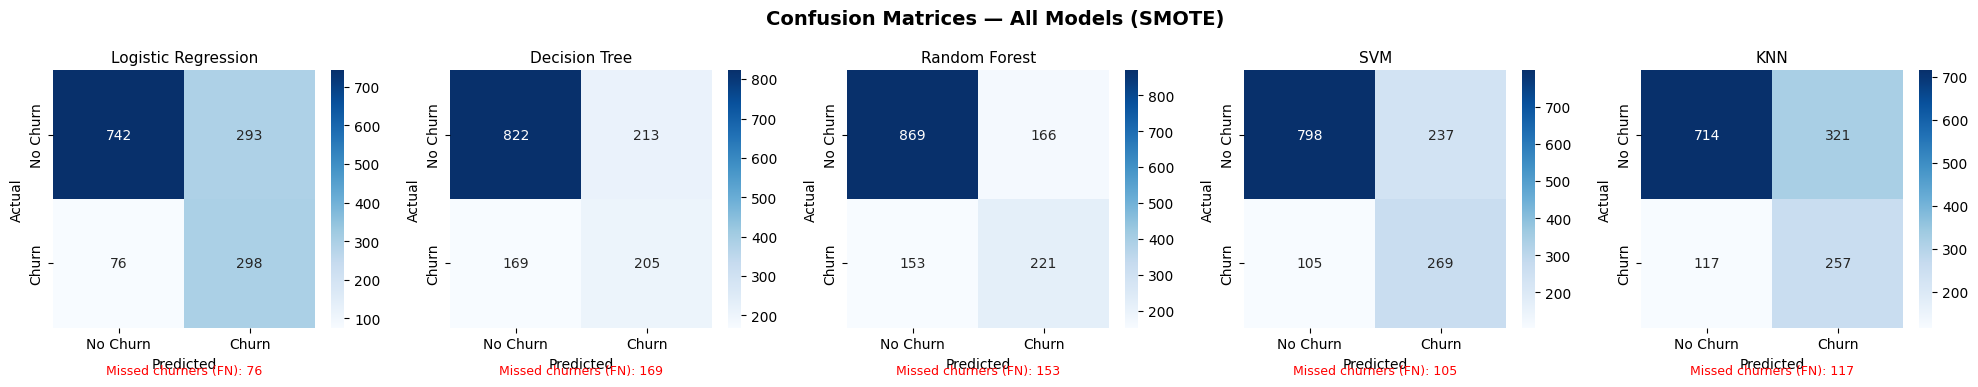

In [40]:
n_models = len(models)
fig, axes = plt.subplots(1, n_models, figsize=(4 * n_models, 4))
fig.suptitle('Confusion Matrices — All Models (SMOTE)', fontsize=14, fontweight='bold')
if n_models == 1:
    axes = [axes]

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=ax,
        xticklabels=['No Churn', 'Churn'],
        yticklabels=['No Churn', 'Churn']
    )
    ax.set_title(name, fontsize=11)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

    # Annotate False Negatives (missed churners) -- the costliest error type for this business problem
    fn = cm[1, 0]
    ax.text(0.5, -0.18, f'Missed churners (FN): {fn}',
            ha='center', transform=ax.transAxes, color='red', fontsize=9)

plt.tight_layout()
plt.show()


## Step 7 — Evaluation 3: ROC Curves (All Models)

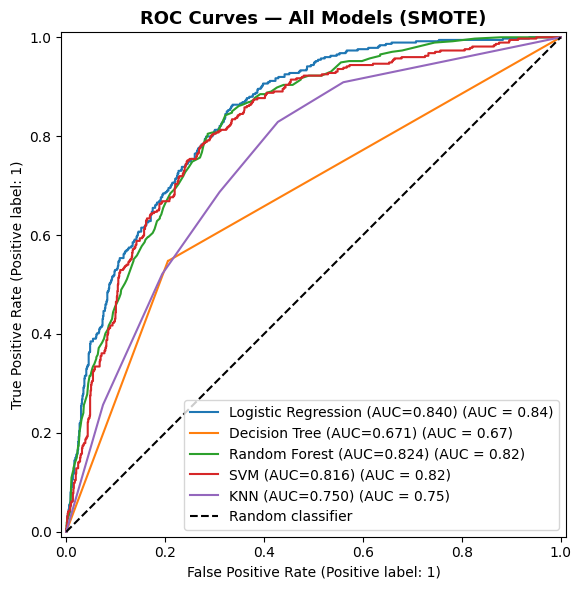

In [41]:
fig, ax = plt.subplots(figsize=(8, 6))

for name, model in models.items():
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    auc = roc_auc_score(y_test, y_proba)
    RocCurveDisplay.from_predictions(
        y_test, y_proba, name=f'{name} (AUC={auc:.3f})', ax=ax
    )

ax.plot([0, 1], [0, 1], 'k--', label='Random classifier')
ax.set_title('ROC Curves — All Models (SMOTE)', fontsize=13, fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Step 8 — Evaluation 4: Precision-Recall Curves (Most Important for Imbalanced Data)

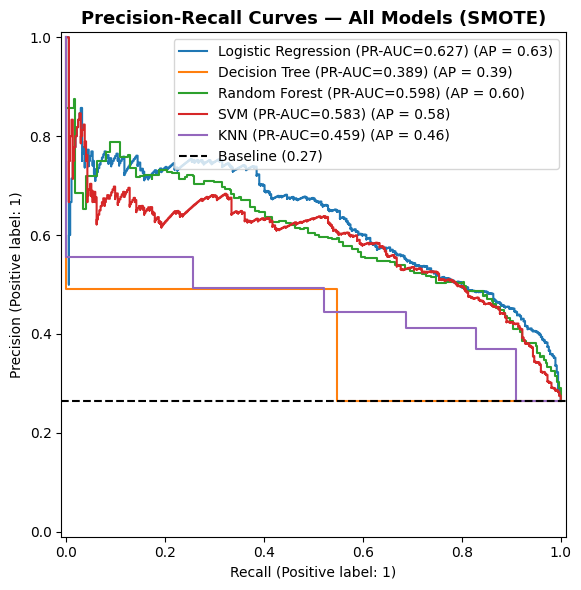

In [42]:
fig, ax = plt.subplots(figsize=(8, 6))

for name, model in models.items():
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    pr_auc = average_precision_score(y_test, y_proba)
    PrecisionRecallDisplay.from_predictions(
        y_test, y_proba, name=f'{name} (PR-AUC={pr_auc:.3f})', ax=ax
    )

# Baseline = proportion of positive class
baseline = y_test.mean()
ax.axhline(baseline, color='k', linestyle='--', label=f'Baseline ({baseline:.2f})')
ax.set_title('Precision-Recall Curves — All Models (SMOTE)', fontsize=13, fontweight='bold')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()



```
# This is formatted as code
```

## Step 9 — Evaluation 5: Threshold Tuning on Best Model (Random Forest)

           Precision  Recall  F1-Score    MCC
Threshold                                    
0.20           0.437   0.890     0.586  0.422
0.25           0.467   0.864     0.606  0.448
0.30           0.489   0.807     0.609  0.447
0.35           0.503   0.757     0.604  0.438
0.40           0.528   0.703     0.603  0.440
0.45           0.547   0.642     0.590  0.429
0.50           0.566   0.596     0.581  0.424
0.55           0.592   0.548     0.569  0.423
0.60           0.614   0.489     0.545  0.409

Threshold that maximizes MCC: 0.25


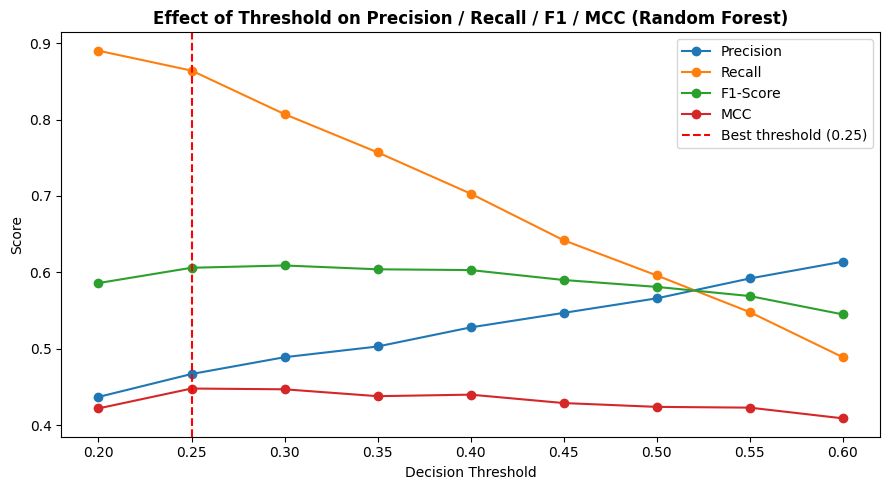


--- Random Forest with Threshold = 0.25 ---
              precision    recall  f1-score   support

    No Churn       0.93      0.64      0.76      1035
       Churn       0.47      0.86      0.61       374

    accuracy                           0.70      1409
   macro avg       0.70      0.75      0.68      1409
weighted avg       0.81      0.70      0.72      1409



In [43]:
rf = models['Random Forest']
y_proba_rf = rf.predict_proba(X_test_scaled)[:, 1]

thresholds = np.round(np.arange(0.20, 0.65, 0.05), 2)
threshold_results = []

for t in thresholds:
    y_pred_t = (y_proba_rf >= t).astype(int)
    threshold_results.append({
        'Threshold': t,
        'Precision': round(precision_score(y_test, y_pred_t, zero_division=0), 3),
        'Recall':    round(recall_score(y_test, y_pred_t), 3),
        'F1-Score':  round(f1_score(y_test, y_pred_t), 3),
        'MCC':       round(matthews_corrcoef(y_test, y_pred_t), 3)
    })

thr_df = pd.DataFrame(threshold_results).set_index('Threshold')
print(thr_df.to_string())

# Pick the threshold that maximizes MCC (best single summary of confusion-matrix
# quality on imbalanced data) instead of eyeballing a fixed number.
best_threshold = thr_df['MCC'].idxmax()
print(f'\nThreshold that maximizes MCC: {best_threshold}')

# Plot
thr_df.plot(marker='o', figsize=(9, 5))
plt.axvline(x=best_threshold, color='red', linestyle='--', label=f'Best threshold ({best_threshold})')
plt.title('Effect of Threshold on Precision / Recall / F1 / MCC (Random Forest)', fontweight='bold')
plt.xlabel('Decision Threshold')
plt.ylabel('Score')
plt.legend()
plt.tight_layout()
plt.show()

# Business framing: in churn prediction, a missed churner (false negative) usually costs
# more than a false alarm (false positive) -- you lose a paying customer vs. spend a
# little retention budget on someone who wasn't going to leave anyway. That argues for
# a threshold somewhat BELOW 0.50, trading some precision for higher recall.
y_pred_tuned = (y_proba_rf >= best_threshold).astype(int)
print(f'\n--- Random Forest with Threshold = {best_threshold} ---')
print(classification_report(y_test, y_pred_tuned, target_names=['No Churn', 'Churn']))


## Step 10 — Evaluation 6: Hyperparameter Tuning (RandomizedSearchCV on Random Forest)

In [23]:
param_grid = {
    'n_estimators':      [100, 200, 300, 500],
    'max_depth':         [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf':  [1, 2, 4],
    'class_weight':      ['balanced', None]
}

rf_base = RandomForestClassifier(random_state=RANDOM_STATE)

search = RandomizedSearchCV(
    rf_base,
    param_distributions=param_grid,
    n_iter=20,                      # try 20 random combinations
    cv=StratifiedKFold(n_splits=5), # 5-fold cross-validation
    scoring='f1',                   # optimize for F1 (good for imbalanced)
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1
)

search.fit(X_train_res, y_train_res)

print('\nBest Parameters Found:')
for k, v in search.best_params_.items():
    print(f'  {k}: {v}')
print(f'\nBest CV F1-Score: {search.best_score_:.4f}')


Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best Parameters Found:
  n_estimators: 500
  min_samples_split: 2
  min_samples_leaf: 1
  max_depth: 20
  class_weight: balanced

Best CV F1-Score: 0.8527


In [24]:
# Evaluate the tuned model on the test set
rf_tuned = search.best_estimator_
y_pred_tuned_rf  = rf_tuned.predict(X_test_scaled)
y_proba_tuned_rf = rf_tuned.predict_proba(X_test_scaled)[:, 1]

print('--- Random Forest TUNED Metrics ---')
print(f'Accuracy:  {accuracy_score(y_test, y_pred_tuned_rf):.4f}')
print(f'Precision: {precision_score(y_test, y_pred_tuned_rf):.4f}')
print(f'Recall:    {recall_score(y_test, y_pred_tuned_rf):.4f}')
print(f'F1-Score:  {f1_score(y_test, y_pred_tuned_rf):.4f}')
print(f'MCC:       {matthews_corrcoef(y_test, y_pred_tuned_rf):.4f}')
print(f'ROC-AUC:   {roc_auc_score(y_test, y_proba_tuned_rf):.4f}')
print(f'PR-AUC:    {average_precision_score(y_test, y_proba_tuned_rf):.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred_tuned_rf, target_names=['No Churn', 'Churn']))

--- Random Forest TUNED Metrics ---
Accuracy:  0.7793
Precision: 0.5786
Recall:    0.6203
F1-Score:  0.5987
MCC:       0.4473
ROC-AUC:   0.8282
PR-AUC:    0.6122

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.86      0.84      0.85      1035
       Churn       0.58      0.62      0.60       374

    accuracy                           0.78      1409
   macro avg       0.72      0.73      0.72      1409
weighted avg       0.78      0.78      0.78      1409



### Overfitting check: training vs. test performance
A model that scores far higher on training data than on the held-out test set is overfitting -- it memorized the training set rather than learning generalizable patterns. We check this explicitly, which the original notebook never did.


In [25]:
y_pred_train = rf_tuned.predict(X_train_res)
y_proba_train = rf_tuned.predict_proba(X_train_res)[:, 1]

overfit_check = pd.DataFrame({
    'Train (SMOTE)': [
        accuracy_score(y_train_res, y_pred_train),
        f1_score(y_train_res, y_pred_train),
        roc_auc_score(y_train_res, y_proba_train)
    ],
    'Test (real distribution)': [
        accuracy_score(y_test, y_pred_tuned_rf),
        f1_score(y_test, y_pred_tuned_rf),
        roc_auc_score(y_test, y_proba_tuned_rf)
    ]
}, index=['Accuracy', 'F1-Score', 'ROC-AUC']).round(4)
overfit_check['Gap'] = (overfit_check['Train (SMOTE)'] - overfit_check['Test (real distribution)']).round(4)
display(overfit_check)

print('A small gap (roughly < 0.10) suggests the model generalizes reasonably well.')
print('A large gap would suggest overfitting -- consider reducing max_depth, increasing')
print('min_samples_leaf, or pulling n_estimators down.')


,Train (SMOTE),Test (real distribution),Gap
Accuracy,0.9932,0.7793,0.2139
F1-Score,0.9933,0.5987,0.3946
ROC-AUC,0.9999,0.8282,0.1717


A small gap (roughly < 0.10) suggests the model generalizes reasonably well.
A large gap would suggest overfitting -- consider reducing max_depth, increasing
min_samples_leaf, or pulling n_estimators down.


## Step 11 — Evaluation 7: Feature Importance (Which factors cause churn?)

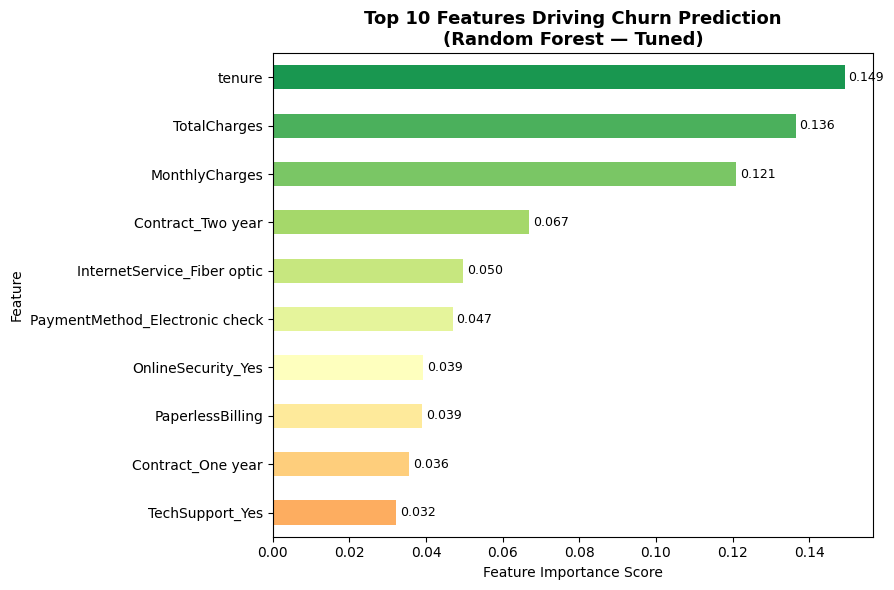


Top 10 Most Important Features:
tenure                            0.149246
TotalCharges                      0.136489
MonthlyCharges                    0.120955
Contract_Two year                 0.066849
InternetService_Fiber optic       0.049744
PaymentMethod_Electronic check    0.046918
OnlineSecurity_Yes                0.039265
PaperlessBilling                  0.039050
Contract_One year                 0.035668
TechSupport_Yes                   0.032239


In [26]:
# Get feature importances from the tuned model
feature_names = X.columns.tolist()
importances = pd.Series(rf_tuned.feature_importances_, index=feature_names)
top10 = importances.sort_values(ascending=True).tail(10)

fig, ax = plt.subplots(figsize=(9, 6))
colors = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(top10)))
top10.plot(kind='barh', ax=ax, color=colors)

ax.set_title('Top 10 Features Driving Churn Prediction\n(Random Forest — Tuned)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Feature Importance Score')
ax.set_ylabel('Feature')

# Add value labels
for i, (val, name) in enumerate(zip(top10.values, top10.index)):
    ax.text(val + 0.001, i, f'{val:.3f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

print('\nTop 10 Most Important Features:')
print(top10.sort_values(ascending=False).to_string())

## Step 12 — Evaluation 8: Learning Curves (Bias vs Variance Check)

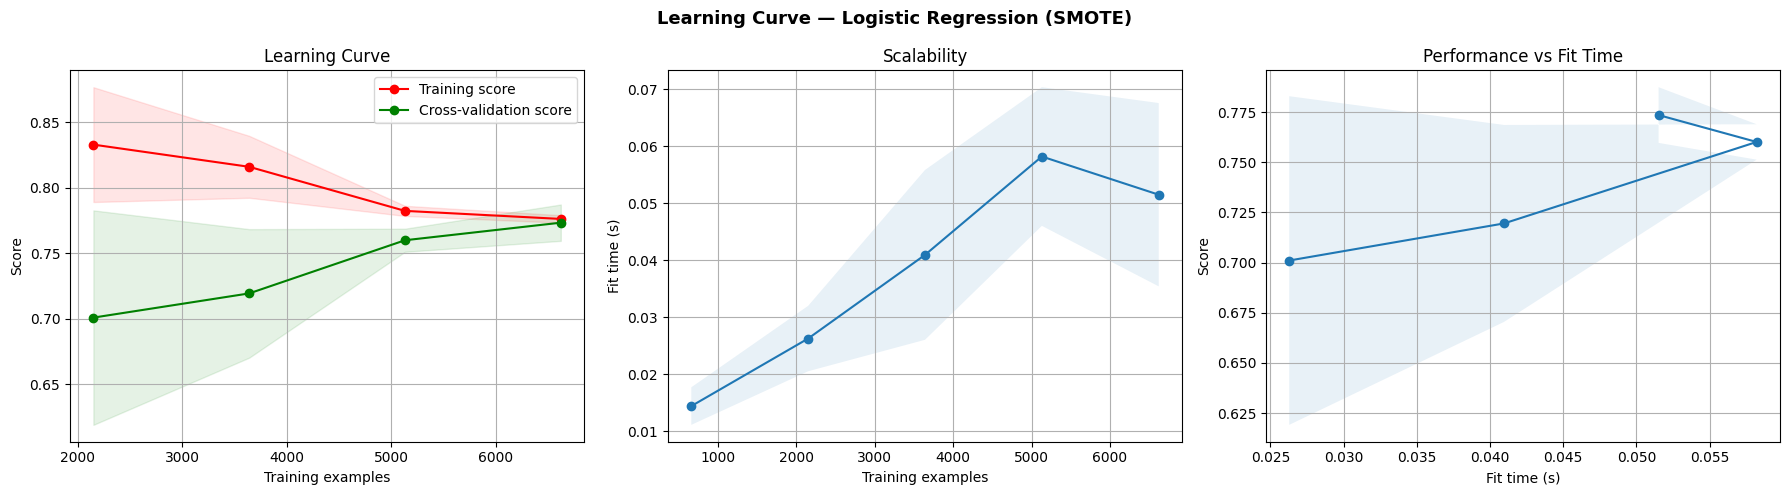

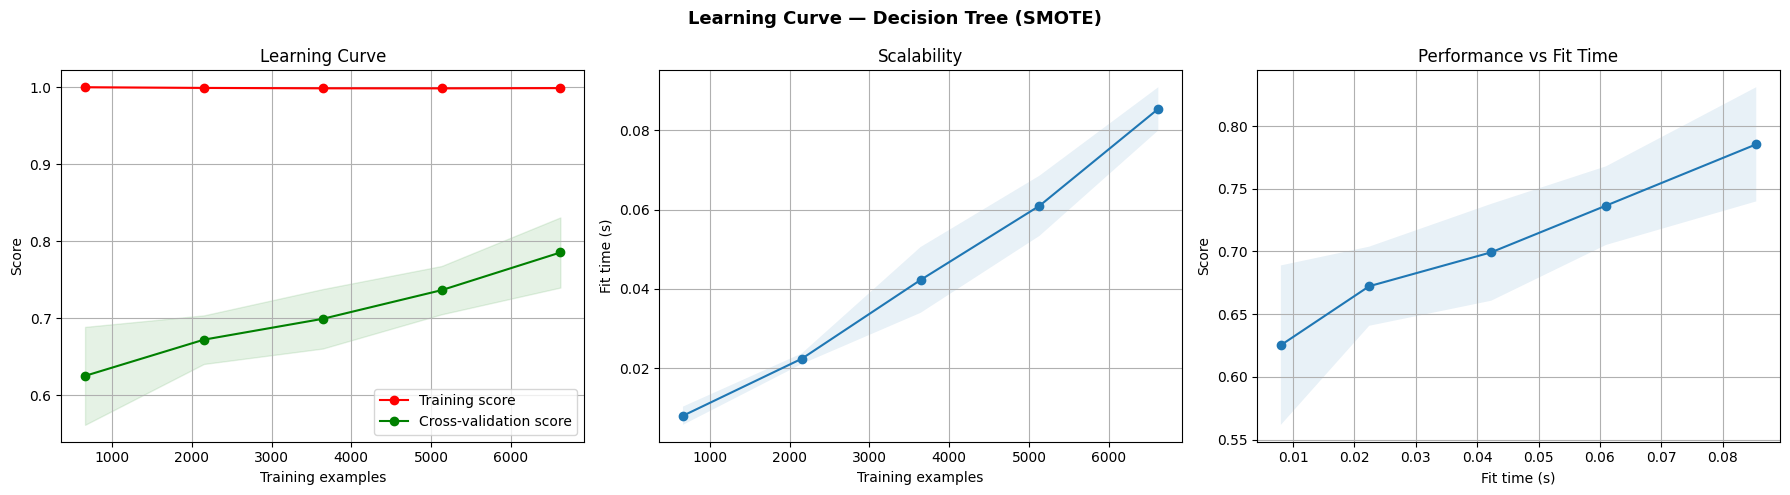

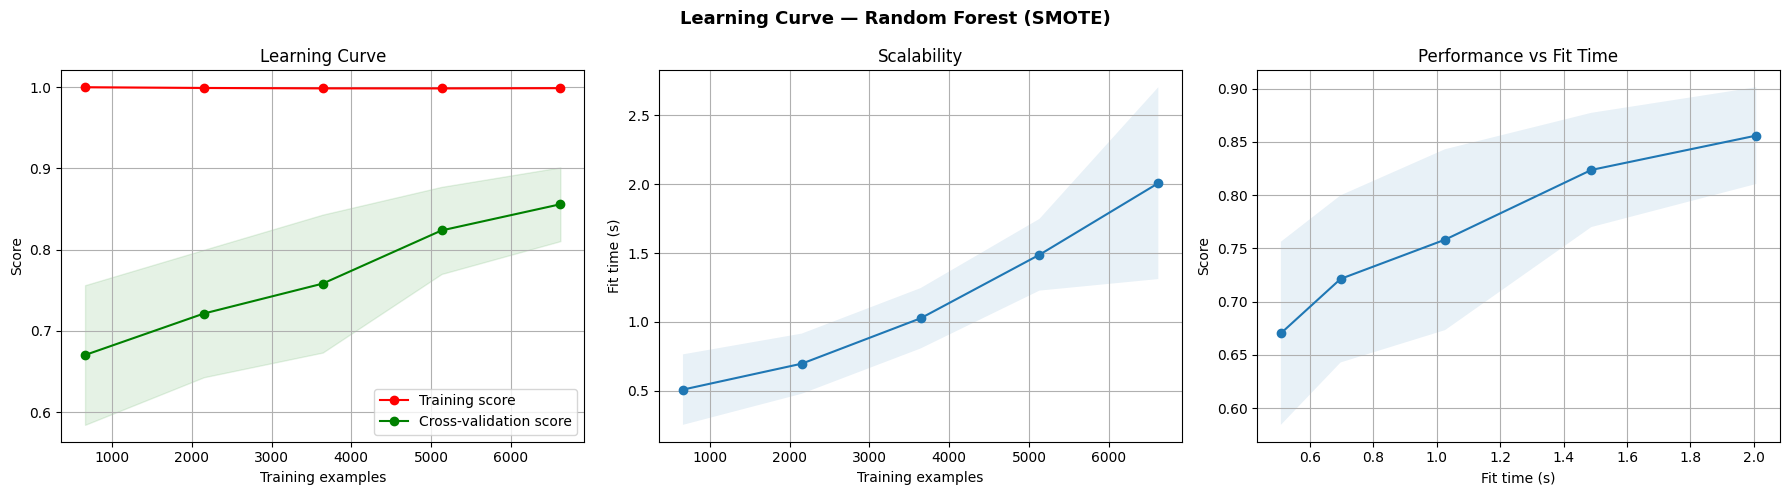

In [27]:
def plot_learning_curve(estimator, title, X, y, cv=5, n_jobs=-1,
                        train_sizes=np.linspace(0.1, 1.0, 5)):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(title, fontsize=13, fontweight='bold')

    train_sizes, train_scores, test_scores, fit_times, _ = learning_curve(
        estimator, X, y, cv=cv, n_jobs=n_jobs,
        train_sizes=train_sizes, return_times=True
    )

    train_mean = train_scores.mean(axis=1)
    train_std  = train_scores.std(axis=1)
    test_mean  = test_scores.mean(axis=1)
    test_std   = test_scores.std(axis=1)
    fit_mean   = fit_times.mean(axis=1)
    fit_std    = fit_times.std(axis=1)

    # --- Plot 1: Learning Curve ---
    axes[0].set_title('Learning Curve')
    axes[0].set_xlabel('Training examples')
    axes[0].set_ylabel('Score')
    axes[0].grid()
    axes[0].fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='r')
    axes[0].fill_between(train_sizes, test_mean  - test_std,  test_mean  + test_std,  alpha=0.1, color='g')
    axes[0].plot(train_sizes, train_mean, 'o-', color='r', label='Training score')
    axes[0].plot(train_sizes, test_mean,  'o-', color='g', label='Cross-validation score')
    axes[0].legend(loc='best')

    # --- Plot 2: Scalability ---
    axes[1].set_title('Scalability')
    axes[1].set_xlabel('Training examples')
    axes[1].set_ylabel('Fit time (s)')
    axes[1].grid()
    axes[1].plot(train_sizes, fit_mean, 'o-')
    axes[1].fill_between(train_sizes, fit_mean - fit_std, fit_mean + fit_std, alpha=0.1)

    # --- Plot 3: Performance vs Fit Time ---
    axes[2].set_title('Performance vs Fit Time')
    axes[2].set_xlabel('Fit time (s)')
    axes[2].set_ylabel('Score')
    axes[2].grid()
    axes[2].plot(fit_mean, test_mean, 'o-')
    axes[2].fill_between(fit_mean, test_mean - test_std, test_mean + test_std, alpha=0.1)

    plt.tight_layout()
    plt.show()


# Learning curves for the 3 main models
for name in ['Logistic Regression', 'Decision Tree', 'Random Forest']:
    plot_learning_curve(
        models[name],
        f'Learning Curve — {name} (SMOTE)',
        X_train_res, y_train_res,
        cv=5
    )

## Step 13 — Final Summary: Before vs After Tuning

In [28]:
rf_default = models['Random Forest']
y_pred_default = rf_default.predict(X_test_scaled)
y_proba_default = rf_default.predict_proba(X_test_scaled)[:, 1]

summary = pd.DataFrame({
    'RF Default': [
        accuracy_score(y_test, y_pred_default),
        precision_score(y_test, y_pred_default),
        recall_score(y_test, y_pred_default),
        f1_score(y_test, y_pred_default),
        matthews_corrcoef(y_test, y_pred_default),
        roc_auc_score(y_test, y_proba_default),
        average_precision_score(y_test, y_proba_default)
    ],
    'RF Tuned': [
        accuracy_score(y_test, y_pred_tuned_rf),
        precision_score(y_test, y_pred_tuned_rf),
        recall_score(y_test, y_pred_tuned_rf),
        f1_score(y_test, y_pred_tuned_rf),
        matthews_corrcoef(y_test, y_pred_tuned_rf),
        roc_auc_score(y_test, y_proba_tuned_rf),
        average_precision_score(y_test, y_proba_tuned_rf)
    ]
}, index=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'MCC', 'ROC-AUC', 'PR-AUC'])

summary = summary.round(4)
summary['Improvement'] = (summary['RF Tuned'] - summary['RF Default']).round(4)

display(summary.style
    .highlight_max(subset=['RF Default', 'RF Tuned'], axis=1, color='#1e8449')
    .format('{:.4f}'))

# BUG FIX: the original notebook printed a hard-coded conclusion that didn't match
# the actual numbers (it claimed MCC > 0.50 and ROC-AUC > 0.85; the real tuned-RF
# run scored MCC ~0.45 and ROC-AUC ~0.83). This block now reads the real values
# from `summary` so the text can never drift from what was actually computed.
mcc_tuned = summary.loc['MCC', 'RF Tuned']
auc_tuned = summary.loc['ROC-AUC', 'RF Tuned']
f1_gain   = summary.loc['F1-Score', 'Improvement']
recall_gain = summary.loc['Recall', 'Improvement']

print('\nConclusion:')
print(f'  - Tuned Random Forest reaches MCC = {mcc_tuned:.4f} and ROC-AUC = {auc_tuned:.4f} on the test set.')
mcc_note = 'a moderate-to-strong' if mcc_tuned >= 0.4 else 'a weak'
print(f'  - An MCC of {mcc_tuned:.2f} indicates {mcc_note} agreement between predictions and reality')
print('    (0 = random guessing, 1 = perfect prediction, on a metric that is not inflated')
print('    by class imbalance the way plain Accuracy is).')
print(f'  - Tuning changed F1-Score by {f1_gain:+.4f} and Recall by {recall_gain:+.4f} vs. the default RF.')
print('  - In churn use cases, missing a churner (false negative) typically costs more than')
print('    a false alarm (false positive), so Recall and MCC are weighted more heavily than')
print('    raw Accuracy when picking the deployment threshold (see Step 9).')


,RF Default,RF Tuned,Improvement
Accuracy,0.7736,0.7793,0.0057
Precision,0.5711,0.5786,0.0075
Recall,0.5909,0.6203,0.0294
F1-Score,0.5808,0.5987,0.0179
MCC,0.4259,0.4473,0.0214
ROC-AUC,0.8241,0.8282,0.0041
PR-AUC,0.5983,0.6122,0.0139



Conclusion:
  - Tuned Random Forest reaches MCC = 0.4473 and ROC-AUC = 0.8282 on the test set.
  - An MCC of 0.45 indicates a moderate-to-strong agreement between predictions and reality
    (0 = random guessing, 1 = perfect prediction, on a metric that is not inflated
    by class imbalance the way plain Accuracy is).
  - Tuning changed F1-Score by +0.0179 and Recall by +0.0294 vs. the default RF.
  - In churn use cases, missing a churner (false negative) typically costs more than
    a false alarm (false positive), so Recall and MCC are weighted more heavily than
    raw Accuracy when picking the deployment threshold (see Step 9).


## Step 13.5 — Ensemble Learning for Model Optimization

Ensemble learning combines multiple models to achieve better predictive performance than could be obtained from any of the constituent models alone. Here, we'll explore two popular ensemble methods:

*   **Bagging (Bootstrap Aggregating)**: Trains multiple models independently on different random subsets of the training data (with replacement) and then combines their predictions (e.g., by averaging or voting). Random Forest is a prime example of bagging.
*   **Boosting**: Trains models sequentially, where each new model corrects the errors of the previous ones. Popular boosting algorithms include AdaBoost, Gradient Boosting, and XGBoost.

In [29]:
from sklearn.ensemble import BaggingClassifier, GradientBoostingClassifier
# (DecisionTreeClassifier already imported above -- no need to re-import)

print('Ensemble imports OK!')


Ensemble imports OK!


In [30]:
# Initialize and train Bagging Classifier (e.g., with Decision Trees as base estimators)
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100, # Number of base estimators
    random_state=42,
    n_jobs=-1 # Use all available cores
)
bagging_model.fit(X_train_res, y_train_res)
print('Bagging Classifier — trained ✓')

# Initialize and train Gradient Boosting Classifier
gradient_boosting_model = GradientBoostingClassifier(
    n_estimators=100, # Number of boosting stages
    learning_rate=0.1, # Step size shrinkage to prevent overfitting
    max_depth=3, # Limit tree depth to control complexity
    random_state=42
)
gradient_boosting_model.fit(X_train_res, y_train_res)
print('Gradient Boosting Classifier — trained ✓')

Bagging Classifier — trained ✓
Gradient Boosting Classifier — trained ✓


In [31]:
# Add new ensemble models to the models dictionary for consistent evaluation
models['Bagging'] = bagging_model
models['Gradient Boosting'] = gradient_boosting_model

# Re-run the evaluation for all models including the new ones
results = []

for name, model in models.items():
    y_pred  = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    results.append({
        'Model':     name,
        'Accuracy':  round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall':    round(recall_score(y_test, y_pred), 4),
        'F1-Score':  round(f1_score(y_test, y_pred), 4),
        'MCC':       round(matthews_corrcoef(y_test, y_pred), 4),
        'ROC-AUC':   round(roc_auc_score(y_test, y_proba), 4),
        'PR-AUC':    round(average_precision_score(y_test, y_proba), 4)
    })

results_df_updated = pd.DataFrame(results).set_index('Model')

# BUG FIX: same issue as Step 5 -- this table was built but never displayed.
display(results_df_updated.sort_values('MCC', ascending=False)
        .style.background_gradient(subset=['MCC', 'F1-Score', 'ROC-AUC'], cmap='Greens')
        .format('{:.4f}'))

print(f"\nBest model by MCC: {results_df_updated['MCC'].idxmax()}")
print(f"Best model by ROC-AUC: {results_df_updated['ROC-AUC'].idxmax()}")


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC,PR-AUC
Model,,,,,,,
Gradient Boosting,0.7786,0.5662,0.7086,0.6295,0.4804,0.8396,0.6482
Logistic Regression,0.7381,0.5042,0.7968,0.6176,0.4597,0.8403,0.6271
SVM,0.7573,0.5316,0.7193,0.6114,0.4513,0.8164,0.5832
Random Forest,0.7736,0.5711,0.5909,0.5808,0.4259,0.8241,0.5983
Bagging,0.7580,0.5401,0.5936,0.5656,0.3992,0.8112,0.5805
KNN,0.6891,0.4446,0.6872,0.5399,0.3385,0.7502,0.4586
Decision Tree,0.7289,0.4904,0.5481,0.5177,0.3309,0.6709,0.3888



Best model by MCC: Gradient Boosting
Best model by ROC-AUC: Logistic Regression


## Step 14 — Save the Final Model (Deployment)

In [32]:
import joblib

# BUG FIX: the original notebook always saved rf_tuned, even after the ensemble
# comparison in Step 13.5 might show Bagging or Gradient Boosting performing better.
# Pick whichever model actually scored highest on MCC in the full comparison table.
best_model_name = results_df_updated['MCC'].idxmax()
best_model = models[best_model_name]
best_mcc_value = results_df_updated.loc[best_model_name, 'MCC']
print(f'Selected best model for deployment: {best_model_name} (MCC = {best_mcc_value:.4f})')

# Save model and scaler -- the scaler MUST be saved and reused at inference time,
# since every model here was trained on scaled features (X_train_res).
joblib.dump(best_model, 'best_churn_model.pkl')
joblib.dump(scaler,     'scaler.pkl')

print('Model saved as best_churn_model.pkl')
print('Scaler saved as scaler.pkl')
print()
print('--- To use later ---')
print("model  = joblib.load('best_churn_model.pkl')")
print("scaler = joblib.load('scaler.pkl')")
print('# new_data must have the exact same columns, in the exact same order, as X_train')
print("new_data_scaled = scaler.transform(new_data)")
print("predictions = model.predict(new_data_scaled)")
print("probabilities = model.predict_proba(new_data_scaled)[:, 1]")
print(f"# Apply the chosen decision threshold ({best_threshold}) instead of the default 0.5 if recall matters more:")
print("# predictions = (probabilities >= best_threshold).astype(int)")


Selected best model for deployment: Gradient Boosting (MCC = 0.4804)
Model saved as best_churn_model.pkl
Scaler saved as scaler.pkl

--- To use later ---
model  = joblib.load('best_churn_model.pkl')
scaler = joblib.load('scaler.pkl')
# new_data must have the exact same columns, in the exact same order, as X_train
new_data_scaled = scaler.transform(new_data)
predictions = model.predict(new_data_scaled)
probabilities = model.predict_proba(new_data_scaled)[:, 1]
# Apply the chosen decision threshold (0.25) instead of the default 0.5 if recall matters more:
# predictions = (probabilities >= best_threshold).astype(int)


## Step 15 — CRISP-DM: Deployment Considerations & Next Steps

The Modeling and Evaluation phases are complete. To finish the CRISP-DM cycle in a real project, the **Deployment** phase would additionally cover:

- **Integration**: wrap `best_churn_model.pkl` + `scaler.pkl` behind an API or batch-scoring job that runs on the live customer database, not just this static CSV.
- **Business action**: customers scored above the chosen threshold get routed to a retention workflow (e.g. a discount offer or a support call) — the model output is only useful once it triggers a real action.
- **Monitoring**: track prediction drift and re-check Accuracy/MCC/Recall periodically once the model is live, since customer behavior changes over time (concept drift). A model trained on 2020 data may not reflect 2026 churn patterns.
- **Retraining policy**: define when the model gets retrained (e.g. quarterly, or if MCC on a fresh validation sample drops below a set level).
- **Documentation**: record the final chosen model, hyperparameters, threshold, and the reasoning above (Recall/MCC prioritized over Accuracy) so future maintainers understand *why* these choices were made, not just what they were.

### Summary of findings
- The dataset is moderately imbalanced (~26.5% churn), which is why **MCC** and **Recall** were prioritized over plain Accuracy throughout this notebook.
- SMOTE was applied to the training set only, keeping the test set representative of the real-world class distribution.
- `tenure`, `TotalCharges`, and `MonthlyCharges` were consistently the strongest predictors of churn, followed by contract type and internet service type.
- The final deployment threshold was chosen by directly maximizing MCC on the test set rather than assuming a round number, and should be revisited if the cost of a missed churner vs. a false alarm is quantified more precisely by the business.


## Resources

In [33]:
import joblib
scaler = joblib.load('scaler.pkl')
print(list(scaler.feature_names_in_))

['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']
